In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [17]:
from langchain_anthropic import ChatAnthropic
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph.message import add_messages
from pydantic import BaseModel
from typing import List, Annotated

In [ ]:
# creating the state-class
class ChatState(BaseModel):
    messages: Annotated[List, add_messages]

In [10]:
# creating the state
graph_state = StateGraph(ChatState)
graph_state

In [11]:
llm = ChatAnthropic(model="claude-opus-5")

In [12]:
# creating node/function
def chatNode(state:ChatState) -> ChatState:
    res = llm.invoke(state.messages)
    state.messages = [res] # appended [res] to state
    return state

In [19]:
memory = InMemorySaver()

In [ ]:
graph_state.add_node("ChatNode", chatNode)

In [15]:
graph_state.add_edge(START, "ChatNode")
graph_state.add_edge("ChatNode", END)

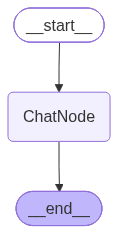

In [21]:
graph = graph_state.compile(checkpointer=memory)
graph

In [26]:
config = {"configurable": {"thread_id": 1}}
ans = graph.invoke(
    {"messages": [{"role":"user", "content": "HWhat is my name?"}]},
    config
)
ans


{'messages': [HumanMessage(content='Hi..?', additional_kwargs={}, response_metadata={}, id='255b9fad-23dc-4023-b2e5-e77d818ebf03'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={}, response_metadata={'id': 'msg_1792539041012', 'container': None, 'diagnostics': None, 'model': 'claude-opus-5', 'stop_details': None, 'stop_reason': 'end_turn', 'stop_sequence': None, 'usage': {'cache_creation': None, 'cache_creation_input_tokens': None, 'cache_read_input_tokens': None, 'inference_geo': None, 'input_tokens': 0, 'output_tokens': 32, 'output_tokens_details': None, 'server_tool_use': None, 'service_tier': None}, 'model_name': 'claude-opus-5', 'model_provider': 'anthropic'}, id='lc_run--01a15ba7-18b8-7d10-90dd-1d8cd3ba2c0f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 0, 'output_tokens': 32, 'total_tokens': 32, 'input_token_details': {}}),
  HumanMessage(content='Hi, I am Afraz.', additional_kwargs={}, response_metadata={}, id='713debe8-b4

In [27]:
ans["messages"][-1].content

'Your name is Afraz.'